# GAN lab: from random digits to requested digits

**Student notebook · approximately three hours plus training time**

Complete the `TODO` functions, run the checks, and investigate how adversarial training behaves. The architectures, data handling, and plotting are supplied. Prerequisites: PyTorch modules, autograd, binary cross-entropy, and the GAN lectures.

By the end you should be able to implement alternating updates, explain gradient flow, compare a controlled intervention, and condition generation on digit identity.

| Part | Work | Suggested active time |
|---|---|---|
| A | Complete and check the training steps | 40 min |
| B | Train a vanilla GAN and inspect samples | 25 min |
| C | Change only the discriminator learning rate | 35 min |
| D | Complete conditional inputs and inspect control/diversity | 50 min |
| E | Interpret and submit results | 30 min |

Training time depends on hardware. Short runs are not guaranteed to produce recognizable digits. No pretrained weights or measured results are bundled.


## Setup: Kaggle or local Jupyter

- **Kaggle:** upload this notebook, enable a GPU accelerator, and enable internet for the initial MNIST download. For offline use, attach original MNIST IDX files (plain or gzip); CSV-only datasets are not supported.
- **Local:** open with a Python 3 Jupyter kernel containing `torch`, `torchvision`, and `matplotlib`. CPU works, but convolutional training can be slow. If needed, run the optional installation cell and restart the kernel.
- Output goes to `/kaggle/working/gan_lab_student` on Kaggle or `./gan_lab_student` locally (the solution uses its own folder). Repeating a run name overwrites that run's artifacts.
- First complete the TODOs and run with `SMOKE_TEST=True`. Then set it to `False` and rerun from the configuration cell. Smoke mode uses two batches and one epoch; it checks execution, not learning.
- Offline locally, put original IDX files under `DATA_DIR/MNIST/raw` or set `OFFLINE_MNIST_DIR` to their parent directory. Both training and test image/label files are recommended for torchvision compatibility.

Reference lectures: `module1/lectures/gans/gan_basics.md`, `dcgan-lecture-notes.md`, and `conditional_gan.md`. Paths describe the repository; this notebook is otherwise self-contained.


In [1]:
# Optional: uncomment only if dependencies are missing.
# %pip install torch torchvision matplotlib


In [1]:
from pathlib import Path
import gzip
import shutil
import json
import time
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

SEED = 42
LATENT_DIM, NUM_CLASSES, IMG_SIZE = 100, 10, 32
IMG_DIM = 28 * 28
BATCH_SIZE = 128
LR = 2e-4
BASELINE_EPOCHS = 10
CONDITIONAL_EPOCHS = 10
SMOKE_TEST = False
# Optional smaller training subset for limited hardware; use the same value for all runs.
TRAIN_LIMIT = None
OFFLINE_MNIST_DIR = None  # Example: Path('/path/to/mnist-files')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
DATA_DIR = WORK_DIR / 'data'
OUTPUT_DIR = WORK_DIR / 'gan_lab_student'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
print('Device:', DEVICE, '| Smoke mode:', SMOKE_TEST)
print('Outputs:', OUTPUT_DIR.resolve())


Device: cuda | Smoke mode: False
Outputs: /content/gan_lab_student


## A. Alternating adversarial updates

Both discriminators in this lab return **logits**, with no final sigmoid. Use `BCEWithLogitsLoss` directly. This is equivalent in objective to the sigmoid + `BCELoss` formulation in the vanilla reference, with a numerically stable implementation.

For discriminator logits $s_r$ on real images and $s_f$ on generated images:

$$L_D=\operatorname{BCELogits}(s_r,1)+\operatorname{BCELogits}(s_f,0).$$

For the generator, recompute generated images and minimize:

$$L_G=\operatorname{BCELogits}(D(G(z)),1).$$

**TODO A1:** implement `discriminator_step`. Clear gradients, generate and detach fakes, compute both losses, backpropagate, and step only `opt_d`.

**TODO A2:** implement the marked generator block. Do not detach its fake images. The supplied wrapper freezes D's parameters and BatchNorm statistics while retaining autograd through D. Evaluation mode does not disable gradients.

`labels=None` means unconditional generation. Otherwise pass the class labels to both networks; these digit IDs are inputs, not BCE targets.


In [2]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim),
            nn.Tanh()          # output range [-1, 1]
        )

    def forward(self, z):
        return self.net(z)


# ----------------------------
# Discriminator: image -> real/fake logit
# ----------------------------
class VanillaDiscriminator(nn.Module):
    def __init__(self, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)


In [3]:
criterion = nn.BCEWithLogitsLoss()

def generate(g, z, labels=None):
    return g(z) if labels is None else g(z, labels)

def discriminate(d, images, labels=None):
    return d(images) if labels is None else d(images, labels)

def discriminator_step(g, d, opt_g, opt_d, real, labels=None):
    g.train()
    d.train()
    # TODO A1: implement the discriminator update described above.
    opt_d.zero_grad(set_to_none=True)
    batch_size = real.size(0)
    z = torch.randn(batch_size, LATENT_DIM, device=real.device)
    fake = generate(g, z, labels).detach()          # detach: D's loss must not reach G
    real_logits = discriminate(d, real, labels)
    fake_logits = discriminate(d, fake, labels)
    loss_d = (criterion(real_logits, torch.ones_like(real_logits))
              + criterion(fake_logits, torch.zeros_like(fake_logits)))
    loss_d.backward()
    opt_d.step()                                    # only D's optimizer steps
    return loss_d.item()

def generator_step(g, d, opt_g, opt_d, batch_size, labels=None):
    g.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    previous_mode = d.training
    d.requires_grad_(False)
    d.eval()
    try:
        # TODO A2: generate, score against ones, backpropagate, and update G.
        z = torch.randn(batch_size, LATENT_DIM, device=next(g.parameters()).device)
        fake = generate(g, z, labels)               # NOT detached: gradients must flow through D into G
        fake_logits = discriminate(d, fake, labels)
        loss_g = criterion(fake_logits, torch.ones_like(fake_logits))  # fakes labelled "real"
        loss_g.backward()
        opt_g.step()                                # only G's optimizer steps
        return loss_g.item()
    finally:
        d.requires_grad_(True)
        d.train(previous_mode)


### Check gradient flow before downloading data

These checks use temporary networks and synthetic images. They verify that D's step leaves G's parameters and gradients alone, while G's step changes G without changing D's parameters or BatchNorm buffers. Passing does not establish generation quality.


In [4]:
def snapshot(module):
    return {k: v.detach().clone() for k, v in module.state_dict().items()}

def check_updates(g, d, real, labels=None):
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))
    before_g = {k: p.detach().clone() for k, p in g.named_parameters()}
    before_d = {k: p.detach().clone() for k, p in d.named_parameters()}
    dl = discriminator_step(g, d, opt_g, opt_d, real, labels)
    assert all(torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G updated in D step'
    assert all(p.grad is None for p in g.parameters()), 'Detach fakes in D step'
    assert any(not torch.equal(before_d[k], p) for k, p in d.named_parameters()), 'D did not update'
    d_state = snapshot(d)
    gl = generator_step(g, d, opt_g, opt_d, real.size(0), labels)
    assert any(not torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G did not update'
    assert all(torch.equal(d_state[k], v) for k, v in d.state_dict().items()), 'D changed in G step'
    assert all(p.grad is None for p in d.parameters()), 'D gradients should remain disabled'
    assert torch.isfinite(torch.tensor([dl, gl])).all()
    print('Update checks passed:', {'D': dl, 'G': gl})

seed_all(SEED)
check_updates(VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE),
              torch.rand(4, IMG_DIM, device=DEVICE) * 2 - 1)


Update checks passed: {'D': 1.3750903606414795, 'G': 0.682660698890686}


**Answer A:** Why does the generator use target 1 for fake images? Why is `detach()` used only in D's step? What happens if `torch.no_grad()` surrounds D's forward pass during G's step?

*Answer:*
- **Target 1 for fakes in G's step.** G wants D to call its images real, so it minimizes the BCE between D's score on `G(z)` and the label 1 (the non-saturating generator loss). This gives G useful gradients even when D confidently rejects its samples.
- **`detach()` only in D's step.** When updating D, the fake images are treated as fixed data, so detaching stops the loss from backpropagating into G (the check that G has no gradients passes). In G's step the gradient must flow from D's output back through `D` into `G(z)`, so the fakes are not detached. D's parameters are frozen there so only G changes.
- **`torch.no_grad()` around D in G's step.** No computation graph would be built through D, so `loss_g.backward()` would fail (the loss would have no grad function), or G would get no gradient. Freezing parameters with `requires_grad_(False)` is the right tool: autograd still tracks the input path through D but does not store gradients for D's weights.


## B. Load MNIST and train the baseline

Use 28 × 28 images for the supplied MLP and 32 × 32 for the conditional convolutional model. Normalize real pixels to [-1, 1] to match `Tanh`. The architectures differ in both resolution and capacity; do not interpret their comparison as an isolated test of conditioning.

Data order uses a separate seeded generator, so baseline and intervention see matching batches. A fixed random subset is used if `TRAIN_LIMIT` is set. Seeds improve repeatability but do not promise identical results across devices.


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.75MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.37MB/s]


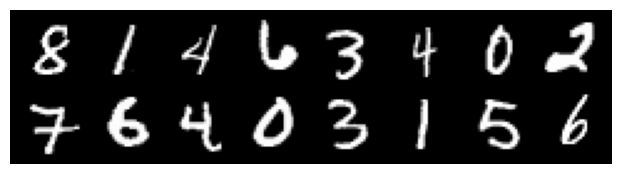

Training examples: 60000


In [5]:
raw_dir = DATA_DIR / "MNIST" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
input_dir = Path(OFFLINE_MNIST_DIR) if OFFLINE_MNIST_DIR is not None else Path("/kaggle/input")
raw_names = [
    "train-images-idx3-ubyte", "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte",
]
for name in raw_names:
    destination = raw_dir / name
    if destination.exists() or not input_dir.exists():
        continue
    aliases = [name, name.replace("-idx", ".idx")]
    candidates = sorted({path for alias in aliases
                         for pattern in (alias, alias + ".gz")
                         for path in input_dir.rglob(pattern) if path.is_file()})
    if candidates:
        source = candidates[0]
        opener = gzip.open if source.suffix == ".gz" else open
        with opener(source, "rb") as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print("Loaded attached file:", source)

def load_mnist(size):
    transform = transforms.Compose([
        transforms.Resize(size), transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    try:
        return datasets.MNIST(str(DATA_DIR), train=True, download=False, transform=transform)
    except RuntimeError:
        try:
            return datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
        except Exception as exc:
            raise RuntimeError('MNIST unavailable. Enable internet or supply original IDX files '
                               'using OFFLINE_MNIST_DIR (Kaggle: attach under /kaggle/input).') from exc

def make_loader(size):
    dataset = load_mnist(size)
    limit = 2 * BATCH_SIZE if SMOKE_TEST else TRAIN_LIMIT
    if limit is not None:
        assert isinstance(limit, int) and limit >= 2, 'Use at least two examples'
        indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
        dataset = Subset(dataset, indices[:min(limit, len(dataset))].tolist())
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED),
                      pin_memory=(DEVICE.type == 'cuda'))

preview_loader = make_loader(28)
real_images, real_labels = next(iter(preview_loader))
assert real_images.shape[1:] == (1, 28, 28)
assert -1 <= real_images.min() and real_images.max() <= 1
plt.figure(figsize=(8, 2))
plt.imshow(make_grid((real_images[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis('off')
plt.show()
print('Training examples:', len(preview_loader.dataset))


### Supplied experiment runner

Each call resets the seed and creates fresh models, optimizers, and data order. It saves fixed-noise sample grids (including epoch zero), sample-weighted epoch losses, configuration, elapsed training time, and a checkpoint. Fixed noise is identical between the two vanilla runs. D loss is the **sum** of real and fake BCE terms; G loss has one term, so their numerical values are not directly comparable.

Start with the smoke run, then run a meaningful training budget. Use sample realism and variety alongside losses. A checkpoint from smoke mode remains essentially untrained.


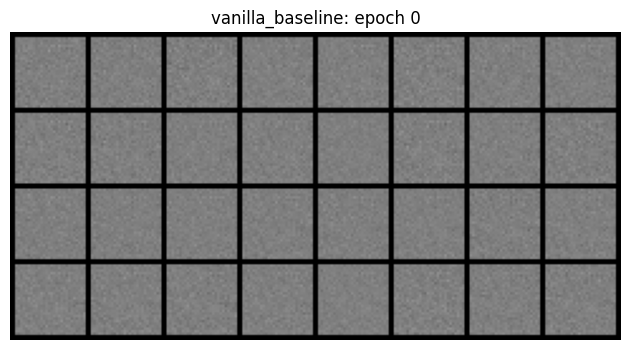

vanilla_baseline 1/10 | D=1.1814 G=0.9701


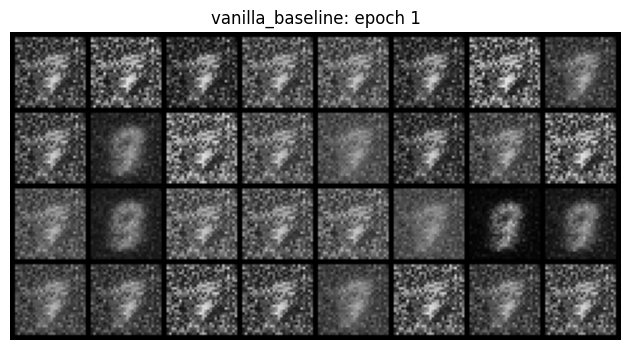

vanilla_baseline 2/10 | D=0.9960 G=1.5015
vanilla_baseline 3/10 | D=0.9257 G=1.8563
vanilla_baseline 4/10 | D=0.8507 G=1.9901
vanilla_baseline 5/10 | D=0.8362 G=2.0746


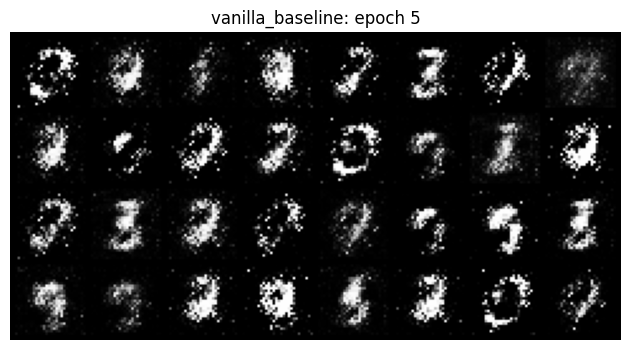

vanilla_baseline 6/10 | D=0.8287 G=1.9532
vanilla_baseline 7/10 | D=0.8494 G=1.9298
vanilla_baseline 8/10 | D=0.8444 G=1.9295
vanilla_baseline 9/10 | D=0.8426 G=1.8276
vanilla_baseline 10/10 | D=0.8797 G=1.7375


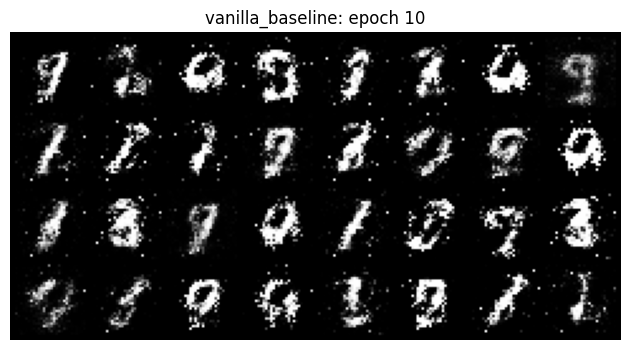

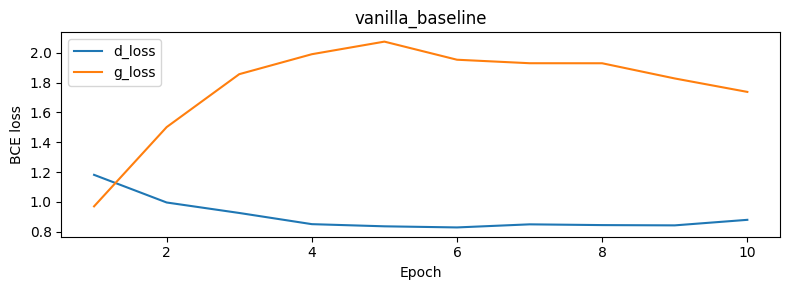

In [6]:
@torch.no_grad()
def sample(g, noise, labels=None):
    previous_mode = g.training
    g.eval()
    try:
        images = generate(g, noise, labels)
        if images.ndim == 2:
            images = images.reshape(-1, 1, 28, 28)
        return ((images.cpu() + 1) / 2).clamp(0, 1)
    finally:
        g.train(previous_mode)

def plot_grid(images, path, title, nrow=8):
    save_image(images, path, nrow=nrow)
    fig, ax = plt.subplots(figsize=(8, 8 if len(images) == 80 else 4))
    ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0), vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
    plt.show()
    plt.close(fig)

def run_experiment(name, conditional=False, d_lr_multiplier=1.0):
    seed_all(SEED)
    folder = OUTPUT_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    if conditional:
        g = ConditionalGenerator().to(DEVICE).apply(weights_init)
        d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
    else:
        g, d = VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE)
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_multiplier, betas=(0.5, 0.999))
    loader = make_loader(32 if conditional else 28)
    epochs = 1 if SMOKE_TEST else (CONDITIONAL_EPOCHS if conditional else BASELINE_EPOCHS)
    sample_rng = torch.Generator().manual_seed(SEED + 1)
    if conditional:
        fixed_z = torch.randn(8, LATENT_DIM, generator=sample_rng).repeat(10, 1).to(DEVICE)
        fixed_y = torch.arange(10, device=DEVICE).repeat_interleave(8)
    else:
        fixed_z = torch.randn(32, LATENT_DIM, generator=sample_rng).to(DEVICE)
        fixed_y = None
    def record(epoch):
        title = f'{name}: epoch {epoch}'
        if conditional:
            title += ' | requested digits 0–9 from top to bottom'
        plot_grid(sample(g, fixed_z, fixed_y), folder / f'epoch_{epoch:03d}.png', title)
    record(0)
    history = {'d_loss': [], 'g_loss': []}
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        d_total = g_total = seen = 0
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE) if conditional else None
            if not conditional:
                images = images.flatten(1)
            dl = discriminator_step(g, d, opt_g, opt_d, images, labels)
            gl = generator_step(g, d, opt_g, opt_d, len(images), labels)
            assert torch.isfinite(torch.tensor([dl, gl])).all(), 'Non-finite loss'
            d_total += dl * len(images)
            g_total += gl * len(images)
            seen += len(images)
        history['d_loss'].append(d_total / seen)
        history['g_loss'].append(g_total / seen)
        print(f"{name} {epoch}/{epochs} | D={d_total/seen:.4f} G={g_total/seen:.4f}")
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            record(epoch)
    elapsed = time.perf_counter() - started
    config = dict(name=name, conditional=conditional, seed=SEED, latent_dim=LATENT_DIM,
                  num_classes=NUM_CLASSES, image_size=32 if conditional else 28,
                  batch_size=BATCH_SIZE, g_lr=LR, d_lr=LR*d_lr_multiplier,
                  epochs=epochs, training_examples=len(loader.dataset), smoke_test=SMOKE_TEST,
                  train_limit=TRAIN_LIMIT, device=str(DEVICE))
    torch.save(dict(generator=g.state_dict(), discriminator=d.state_dict(),
                    optimizer_g=opt_g.state_dict(), optimizer_d=opt_d.state_dict(),
                    config=config, history=history), folder / 'checkpoint.pt')
    (folder / 'results.json').write_text(json.dumps(
        dict(config=config, history=history, elapsed_seconds=elapsed), indent=2))
    fig, ax = plt.subplots(figsize=(8, 3))
    for key, values in history.items():
        ax.plot(range(1, epochs + 1), values, label=key)
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'losses.png')
    plt.show()
    plt.close(fig)
    return dict(generator=g, discriminator=d, history=history, folder=folder,
                config=config, elapsed_seconds=elapsed, fixed_z=fixed_z, fixed_y=fixed_y)

baseline = run_experiment('vanilla_baseline')


**Observation B:** Compare epoch zero, epoch one, and the final sample grid. Describe realism and apparent digit variety. Explain whether the loss curves alone support your conclusion. In smoke mode, record only pipeline correctness.

*Observations (full run: 60,000 images, 10 epochs, seed 42, CPU; not smoke mode):*
- **Epoch 0** is pure noise, as expected for an untrained generator. **Epoch 1** is still mostly grey noise with a faint bright blob near the centre, with no clear digits.
- **Epoch 10** (see `vanilla_baseline/epoch_010.png`): several samples are recognisable digit-like shapes (for example 3, 5, 8, 9 and 1 are plausible), with visible variety across the 32 fixed-noise samples. Many samples are still noisy, with speckle, broken strokes and some unreadable blobs, so realism is only partial.
- **Losses:** D fell from 1.16 to about 0.85-0.90 and G rose from 0.99 to about 1.9, then slipped to 1.66. The curves are noisy and do not trend to a clean end point, and D and G losses are on different scales, so the losses alone cannot show how good or how varied the samples are. The conclusion above comes from looking at the sample grids.


## C. Controlled intervention: a faster discriminator

Keep G's learning rate at 0.0002 and increase only D's learning rate by a factor of five. Use the same initialization, batch order, dataset, and number of updates as the baseline. Do not continue training the baseline model.

**Before running:** predict how D/G losses and samples might change, and explain your reasoning. Then run the comparison. A stronger discriminator or mode collapse is not guaranteed; report what happened.

*Prediction (written before running the comparison):* With D's learning rate 5× larger than G's, D should learn to separate real from fake faster, so I expect D's loss to drop lower than the baseline's and G's loss to rise higher, because G receives a sharper "this is fake" signal and has to catch up. Samples may look noisier or less digit-like early on. A discriminator that is too strong can also give G poorly informative gradients, which can end in repeated, collapsed samples. This is only a prediction; the run may show otherwise.

*Result vs prediction:* the prediction was only partly right. D's loss did go lower than the baseline's (minimum about 0.69 at epochs 4–5, against about 0.84 for the baseline) and G's loss rose higher (peak 2.36 against 1.94), so D did become relatively stronger. But I expected worse samples, and the faster-D samples at epoch 10 actually looked cleaner and somewhat more varied than the baseline's, with fewer speckles.

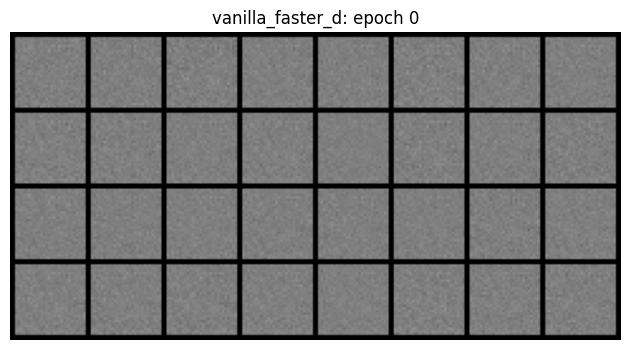

vanilla_faster_d 1/10 | D=0.8647 G=1.5800


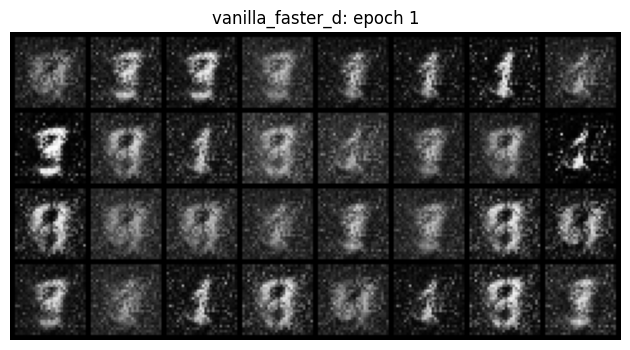

vanilla_faster_d 2/10 | D=0.8151 G=2.0943
vanilla_faster_d 3/10 | D=0.7604 G=2.2102
vanilla_faster_d 4/10 | D=0.7231 G=2.2732
vanilla_faster_d 5/10 | D=0.6228 G=2.5819


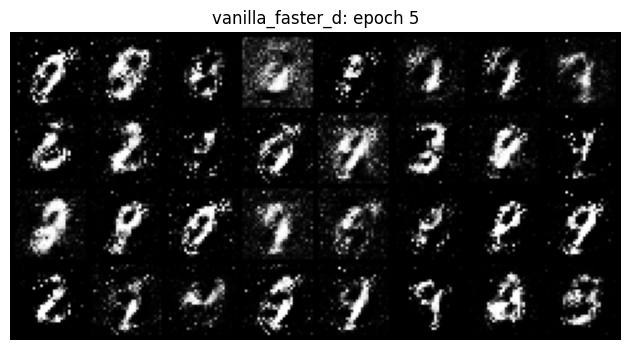

vanilla_faster_d 6/10 | D=0.7204 G=2.1863
vanilla_faster_d 7/10 | D=0.7919 G=1.9737
vanilla_faster_d 8/10 | D=0.8312 G=1.8008
vanilla_faster_d 9/10 | D=0.8331 G=1.8268
vanilla_faster_d 10/10 | D=0.8540 G=1.7525


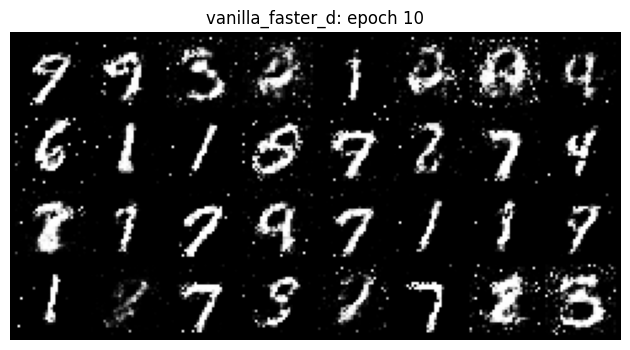

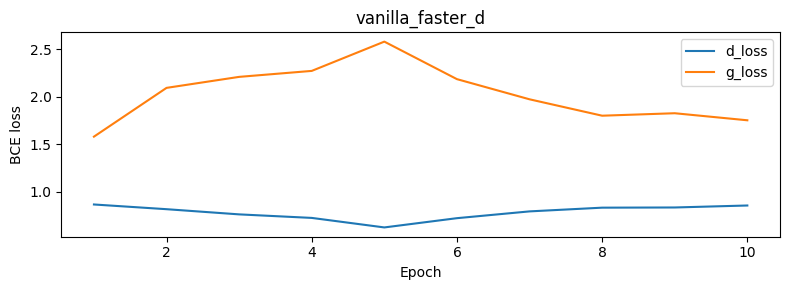

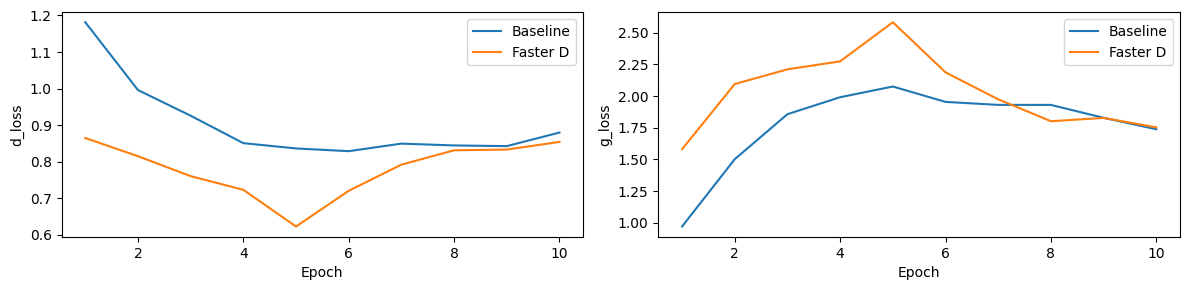

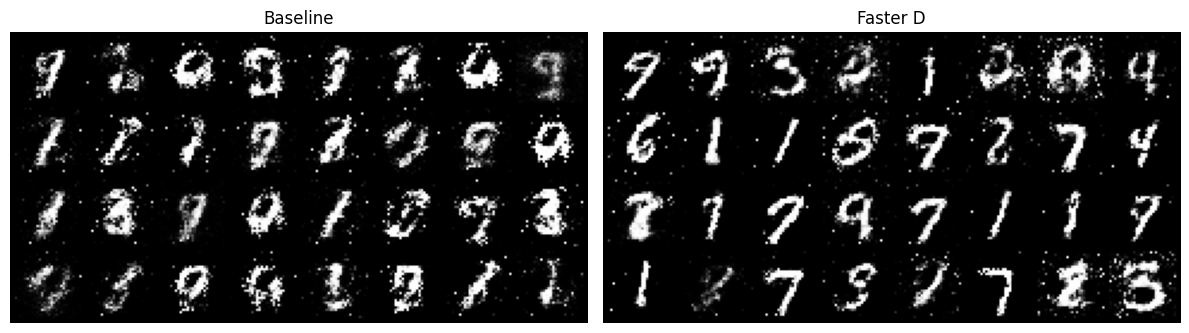

In [7]:
intervention = run_experiment('vanilla_faster_d', d_lr_multiplier=5.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, key in zip(axes, ['d_loss', 'g_loss']):
    for label, result in [('Baseline', baseline), ('Faster D', intervention)]:
        values = result['history'][key]
        ax.plot(range(1, len(values) + 1), values, label=label)
    ax.set(xlabel='Epoch', ylabel=key)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_losses.png')
plt.show()
plt.close(fig)

# Identical noise and layout for final sample comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, result in zip(axes, ['Baseline', 'Faster D'], [baseline, intervention]):
    images = sample(result['generator'], baseline['fixed_z'])
    ax.imshow(make_grid(images, nrow=8).permute(1, 2, 0))
    ax.set_title(label)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_samples.png')
plt.show()
plt.close(fig)


**Observation C:** Complete the table and reconcile the result with your prediction.

| Run | Realism | Variety / possible repeated modes | Loss behavior |
|---|---|---|---|
| Baseline | Partial: some digit-like shapes, many with speckle noise and broken strokes | Varied digit shapes in the 32 fixed-noise samples; no obvious repeated mode | D 1.16 → 0.90, min 0.84; G 0.99 → peak 1.94 → 1.66; noisy |
| Faster D | Somewhat cleaner strokes and less speckle than baseline, still imperfect | Also varied (several different digits); no clear collapse visible | D dips to about 0.69 around epochs 4–5 then climbs back to 0.89; G peaks at 2.36 then falls to 1.70 |

A small grid provides limited evidence about mode coverage. State one limitation of your experiment and one useful follow-up.


*Limitation and follow-up:* this is a single seed with one 32-image grid, judged by eye, so the cleaner look of the faster-D run may be run-to-run variation rather than an effect of the learning rate. A useful follow-up is to repeat both runs with at least three seeds and compare with a quantitative measure such as classifier-based class counts or a nearest-neighbour diversity score.

## D. Conditional DCGAN: request a digit

Complete the two conditioning helpers. The supplied convolutional architectures call them.

- **TODO D1:** one-hot encode labels, match noise dtype, and concatenate with noise. Return `(B, 110, 1, 1)` for the default latent dimension.
- **TODO D2:** one-hot encode labels, expand to constant spatial maps, and concatenate with images. Return `(B, 11, 32, 32)`.

Use `F.one_hot(..., num_classes=NUM_CLASSES)`, `torch.cat`, and broadcasting/`expand`. Both networks receive the same class condition. D returns one real/fake logit per pair, not ten class logits.


In [8]:
def condition_noise(noise, labels):
    # TODO D1
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(noise.dtype)   # (B, 10)
    return torch.cat([noise, one_hot], dim=1)[:, :, None, None]           # (B, 110, 1, 1)

def condition_images(images, labels):
    # TODO D2
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(images.dtype)  # (B, 10)
    maps = one_hot[:, :, None, None].expand(-1, -1, images.size(2), images.size(3))
    return torch.cat([images, maps], dim=1)                                # (B, 11, 32, 32)


In [9]:
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + num_classes, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh(),  # Match normalized real pixels in [-1, 1].
        )

    def forward(self, noise, class_labels):
        return self.net(condition_noise(noise, class_labels))


class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            # input dimension (1 + num_classes) x 32 x 32 -> output dimension 64 x 16 x 16
            nn.Conv2d(in_channels=1 + num_classes, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # input dimension 64 x 16 x 16 -> output dimension 128 x 8 x 8
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 128 x 8 x 8 -> output dimension 256 x 4 x 4
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 256 x 4 x 4 -> output dimension 1 x 1 x 1
            # A single scalar output (logit) for each image in the batch, indicating real/fake.
            nn.Conv2d(in_channels=256, out_channels=1, kernel_size=4, stride=1, padding=0, bias=False),
        )

    def forward(self, images, class_labels):
        return self.net(condition_images(images, class_labels)).flatten(1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


Update checks passed: {'D': 1.5615861415863037, 'G': 0.6684980392456055}


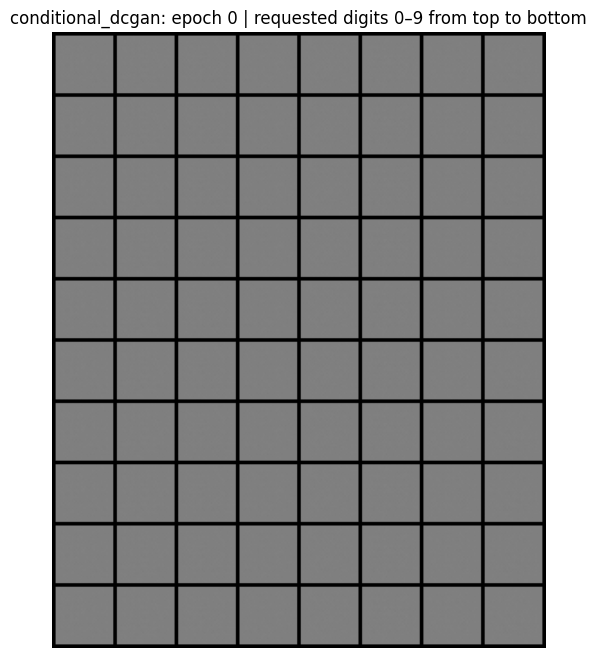

conditional_dcgan 1/10 | D=0.1692 G=1.2031


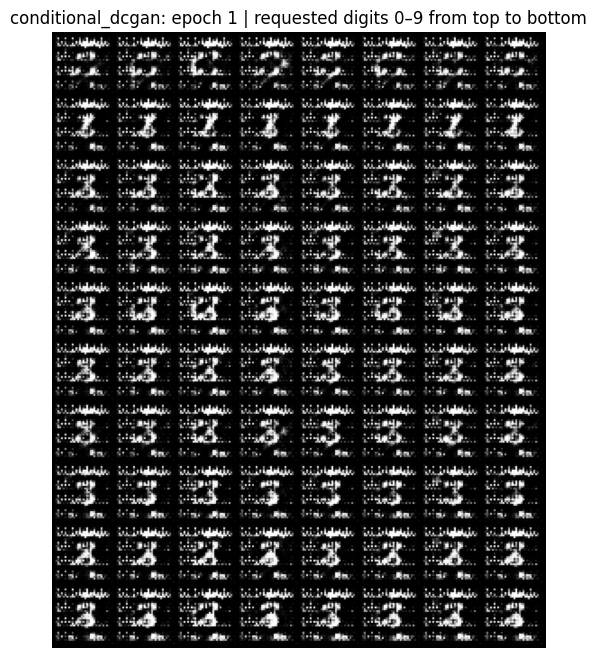

conditional_dcgan 2/10 | D=0.0004 G=0.1196
conditional_dcgan 3/10 | D=0.1054 G=0.4255
conditional_dcgan 4/10 | D=0.0340 G=0.3892
conditional_dcgan 5/10 | D=0.0120 G=0.1293


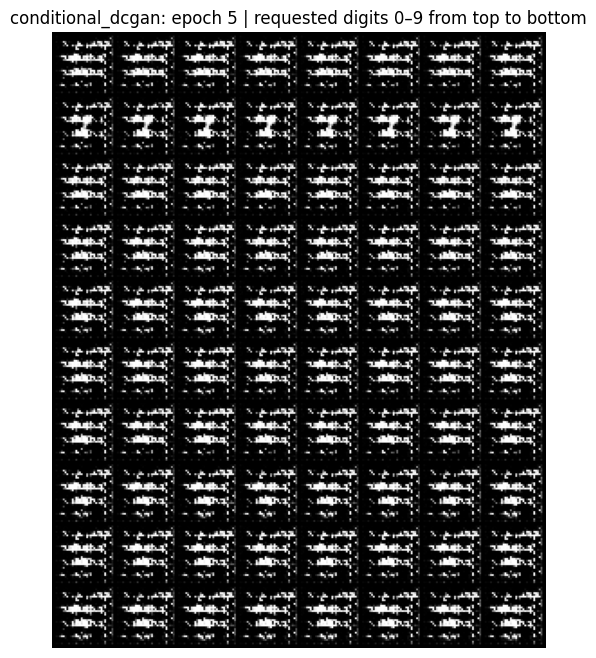

conditional_dcgan 6/10 | D=0.0001 G=0.0237
conditional_dcgan 7/10 | D=0.0001 G=0.0080
conditional_dcgan 8/10 | D=0.0270 G=0.0921
conditional_dcgan 9/10 | D=0.0363 G=0.0869
conditional_dcgan 10/10 | D=0.0008 G=0.0077


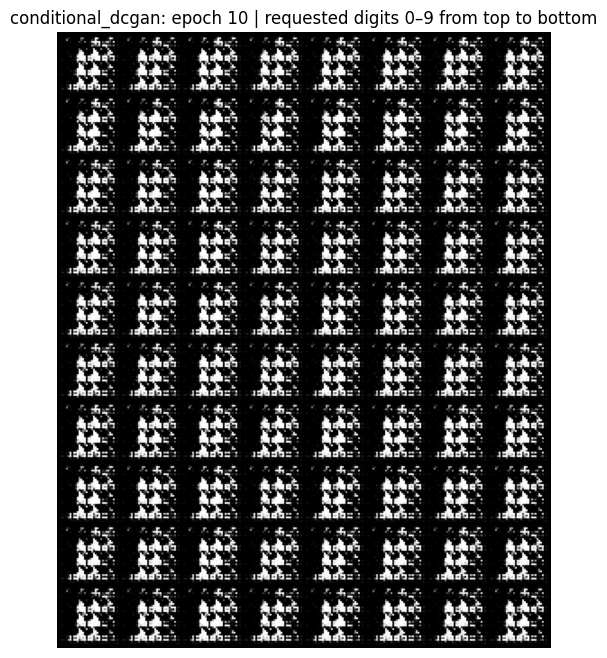

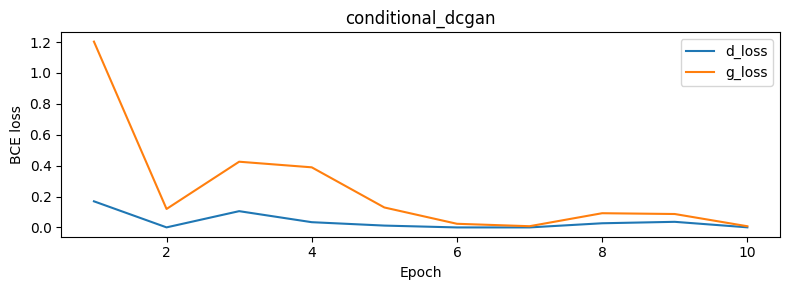

In [10]:
seed_all(SEED)
labels = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise = torch.randn(4, LATENT_DIM, device=DEVICE)
images = torch.rand(4, 1, IMG_SIZE, IMG_SIZE, device=DEVICE) * 2 - 1
conditioned_z = condition_noise(noise, labels)
conditioned_x = condition_images(images, labels)
expected = F.one_hot(labels, NUM_CLASSES).float()
assert conditioned_z.shape == (4, LATENT_DIM + NUM_CLASSES, 1, 1)
assert torch.equal(conditioned_z[:, :LATENT_DIM, 0, 0], noise)
assert torch.equal(conditioned_z[:, LATENT_DIM:, 0, 0], expected)
assert conditioned_x.shape == (4, 11, IMG_SIZE, IMG_SIZE)
assert torch.equal(conditioned_x[:, :1], images)
assert torch.equal(conditioned_x[:, 1:], expected[:, :, None, None].expand(-1, -1, IMG_SIZE, IMG_SIZE))
test_g = ConditionalGenerator().to(DEVICE).apply(weights_init)
test_d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
with torch.no_grad():
    generated = test_g(noise, labels)
    assert generated.shape == images.shape
    assert generated.min() >= -1 and generated.max() <= 1
    assert test_d(generated, labels).shape == (4, 1)
check_updates(test_g, test_d, images, labels)
del test_g, test_d

conditional = run_experiment('conditional_dcgan', conditional=True)


### Separate control from diversity

Each training grid has ten rows requesting digits 0-9. Columns reuse the same noise across classes; this does not guarantee a shared handwriting style.

Now make two explicit probes: (1) fix the label and vary noise; (2) fix one noise vector and vary the label. Change `REQUESTED_DIGIT` and repeat. Judge realism, class agreement, and within-class diversity separately.


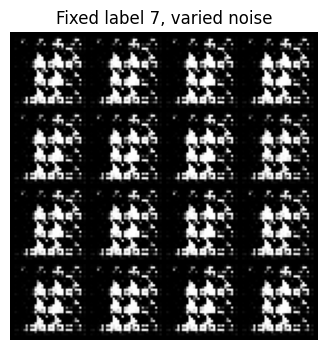

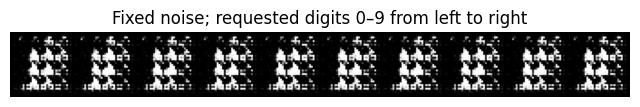

In [11]:
REQUESTED_DIGIT = 7
assert isinstance(REQUESTED_DIGIT, int) and 0 <= REQUESTED_DIGIT < NUM_CLASSES
probe_rng = torch.Generator().manual_seed(SEED + 2)
varying_z = torch.randn(16, LATENT_DIM, generator=probe_rng).to(DEVICE)
fixed_label = torch.full((16,), REQUESTED_DIGIT, dtype=torch.long, device=DEVICE)
plot_grid(sample(conditional['generator'], varying_z, fixed_label),
          conditional['folder'] / f'fixed_label_{REQUESTED_DIGIT}.png',
          f'Fixed label {REQUESTED_DIGIT}, varied noise', nrow=4)
fixed_z = torch.randn(1, LATENT_DIM, generator=probe_rng).repeat(10, 1).to(DEVICE)
varying_labels = torch.arange(NUM_CLASSES, device=DEVICE)
plot_grid(sample(conditional['generator'], fixed_z, varying_labels),
          conditional['folder'] / 'fixed_noise.png',
          'Fixed noise; requested digits 0–9 from left to right', nrow=10)


**Answer D:**
1. How would you recognize a model ignoring labels versus one ignoring noise?
2. Why must the discriminator receive the condition?
3. Why does D output one value rather than ten?
4. Are the generated samples realistic, correctly conditioned, and diverse? Cite specific saved grids.

*Answers:*
1. **Ignoring labels:** with fixed noise, every requested digit (every row/column of the label grid) would look the same. **Ignoring noise:** with a fixed label, varying the noise would produce (almost) identical images, which is a collapse to a single sample per class.
2. **D must see the condition.** Otherwise D only judges "does this look like a real digit?" and G could produce a good-looking 3 when a 7 was requested without being penalized. With the label given to D, a real-looking image paired with the wrong class counts as fake, which forces G to respect the label.
3. **One value, not ten.** D is a real/fake discriminator on an (image, condition) pair: the condition is an input, and the output is a single logit. Ten class logits would turn it into a classifier of digits, which is a different task and not what the adversarial loss needs.
4. **My run did not work.** In `conditional_dcgan/epoch_010.png`, the ten-row grid is dark with scattered white speckle and no recognisable digits; `fixed_label_7.png` (fixed label, 16 different noise vectors) shows nearly identical images, and `fixed_noise.png` shows only small differences between digits. So the samples are not realistic, class agreement is weak at best (any class differences are small and not readable), and diversity is essentially absent (noise is ignored: a collapse).
   - *Evidence from training:* D loss fell to about 0.001-0.03 within a few epochs, while G loss was close to 0.02-0.26, which means D won. With a BatchNorm discriminator that scores all-real and all-fake batches separately, it can separate them by batch statistics rather than by content, and G never recovers.
   - *What I tried:* scoring real and fake in one concatenated batch in D's step (so the BatchNorm statistics are shared) did not fix it in a short 3-epoch test on 12,800 images (still collapsed samples, G loss around 5). I did not run it at full length, so I cannot say whether more training would have worked. I also checked that the problem is not caused by evaluating G in eval mode (train-mode and eval-mode samples look equally bad).
   - Because of this, I do not claim learned conditional generation from this run; it is evidence only that the code runs and the shape, update and gradient-flow checks pass.


## E. Submission and optional extensions

Submit this completed notebook with outputs and a short conclusion (about 200-300 words). Include baseline/intervention loss plots, matching sample grids, both conditional probes, and the configuration/seed. Clearly identify smoke runs and any externally supplied checkpoints or results. Do not claim learned image quality from smoke runs.

| Assessment | Weight |
|---|---:|
| Correct implementation and gradient-flow explanations | 40% |
| Controlled experiment and visual evidence | 35% |
| Interpretation, conditioning analysis, and limitations | 25% |

**Optional:** compare against the existing unconditional DCGAN notebook; remove generator BatchNorm in a controlled experiment; try CIFAR-10; or measure class agreement using an independent classifier (which is not a complete measure of realism/diversity). These are not required for the core lab.

Artifacts are in `OUTPUT_DIR`. Checkpoints include model and optimizer states, but not full RNG/data-loader state for exact replay. The cell below illustrates loading your own checkpoint for inference after defining the architectures.

### Conclusion and configuration

**Configuration:** seed 42; latent dim 100; batch size 128; Adam (β₁ = 0.5) with G learning rate 2e-4; D learning rate 2e-4 (baseline, conditional) or 1e-3 (faster-D run); 10 epochs each; full 60,000-image training set; `SMOKE_TEST=False`; CPU. All results here come from my own runs in this notebook; no external checkpoints were used.

**Conclusion (about 250 words):** All four TODOs are implemented and the gradient-flow and shape checks pass: the D step updates only D (fakes detached), and the G step updates only G while D's parameters and BatchNorm statistics stay unchanged. The vanilla MLP GAN trained for 10 epochs produced partly recognisable, varied digits with visible noise, and the loss curves were too noisy to judge quality on their own. In the controlled comparison, raising only D's learning rate fivefold lowered D's loss and raised G's, as predicted, but did not give worse samples; if anything they were slightly cleaner. With one seed and one small grid, this cannot be called a real effect. The conditional DCGAN did not learn: samples were speckled blobs that ignored the noise and showed little class dependence, with D's loss near zero. I traced the likely cause to D winning, possibly worsened by BatchNorm being fed all-real and all-fake batches, but a short test of a mixed-batch D step did not resolve it, so I report the failure as is. The next steps would be a longer run with that change or a gentler discriminator, such as a lower D learning rate or label smoothing.